# Tarea 6 - Bessel

## 1. Ejercicio de Bessel

### b) Gráfica de $$F(\lambda)$$ en función de $$\lambda$$

Del numeral anterior, la función característica es

$$
F(\lambda)
=
J_0(\lambda R_1)Y_0(\lambda R_2)
-
Y_0(\lambda R_1)J_0(\lambda R_2).
$$

Para $$R_1=1$$ y $$R_2=2$$,

$$
F(\lambda)
=
J_0(\lambda)Y_0(2\lambda)
-
Y_0(\lambda)J_0(2\lambda).
$$

Se grafica $$F(\lambda)$$ para estimar los tres primeros valores de $$\lambda$$ en los que la función cruza el eje horizontal.

### Graficación de la función característica

Se utilizan las funciones de Bessel de orden cero de primera y segunda especie, disponibles en `scipy.special`.

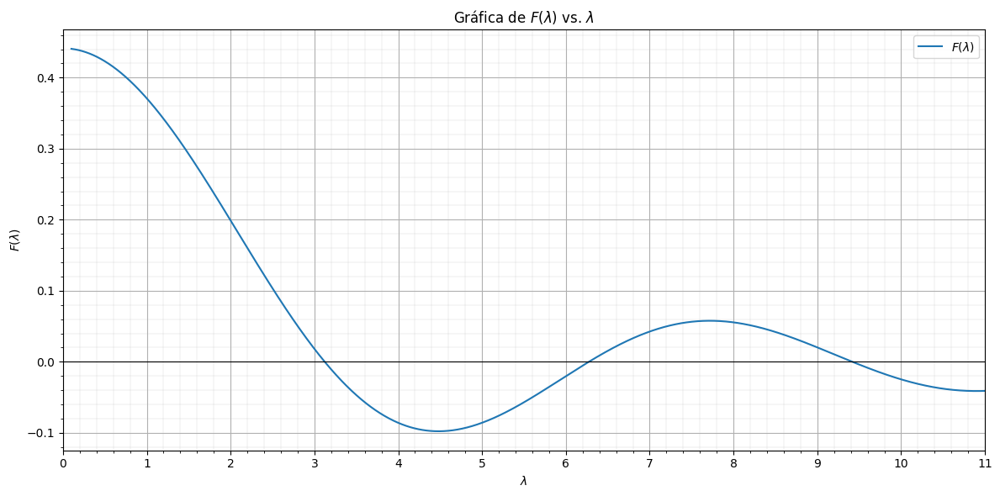

In [3]:
from matplotlib.ticker import MultipleLocator

plt.figure(figsize=(12, 6))
plt.plot(lam, F_lam, label=r"$F(\lambda)$")
plt.axhline(0, color="black", linewidth=0.8)

plt.xlim(0, 11)
plt.xlabel(r"$\lambda$")
plt.ylabel(r"$F(\lambda)$")
plt.title(r"Gráfica de $F(\lambda)$ vs. $\lambda$")

ax = plt.gca()

# Cuadrícula principal
ax.xaxis.set_major_locator(MultipleLocator(1))
ax.yaxis.set_major_locator(MultipleLocator(0.1))

# Cuadrícula secundaria
ax.xaxis.set_minor_locator(MultipleLocator(0.2))
ax.yaxis.set_minor_locator(MultipleLocator(0.02))

ax.grid(which="major", linewidth=0.8)
ax.grid(which="minor", linewidth=0.3, alpha=0.5)

plt.legend()
plt.tight_layout()
plt.show()

### Estimación de los autovalores

A partir de los cruces de la gráfica con el eje horizontal, se estiman los tres primeros valores con una cifra decimal:

$$
\lambda_1 \approx 3.1, \qquad
\lambda_2 \approx 6.3, \qquad
\lambda_3 \approx 9.4.
$$

Estos valores se estiman visualmente a partir de la gráfica; no se calculan las raíces mediante un método numérico.

### c) Gráfica de los autovectores $$U_n(r)$$ en función de $$r$$

Se utilizan los autovalores estimados en el apartado anterior:

$$
\lambda_1 \approx 3.1,\qquad
\lambda_2 \approx 6.3,\qquad
\lambda_3 \approx 9.4.
$$

A partir de

$$
U_n(r)=A J_0(\lambda_n r)+B Y_0(\lambda_n r),
$$

se puede escoger una combinación que satisfaga la condición de borde interior $$U_n(R_1)=0$$:

$$
U_n(r)=J_0(\lambda_n r)Y_0(\lambda_n R_1)
-Y_0(\lambda_n r)J_0(\lambda_n R_1).
$$

La amplitud de un autovector es arbitraria, por lo que se normaliza cada curva dividiéndola por su máximo valor absoluto para facilitar la comparación. Como los autovalores se estimaron visualmente con una cifra decimal, las curvas pueden no ser exactamente cero en $$r=R_2$$.

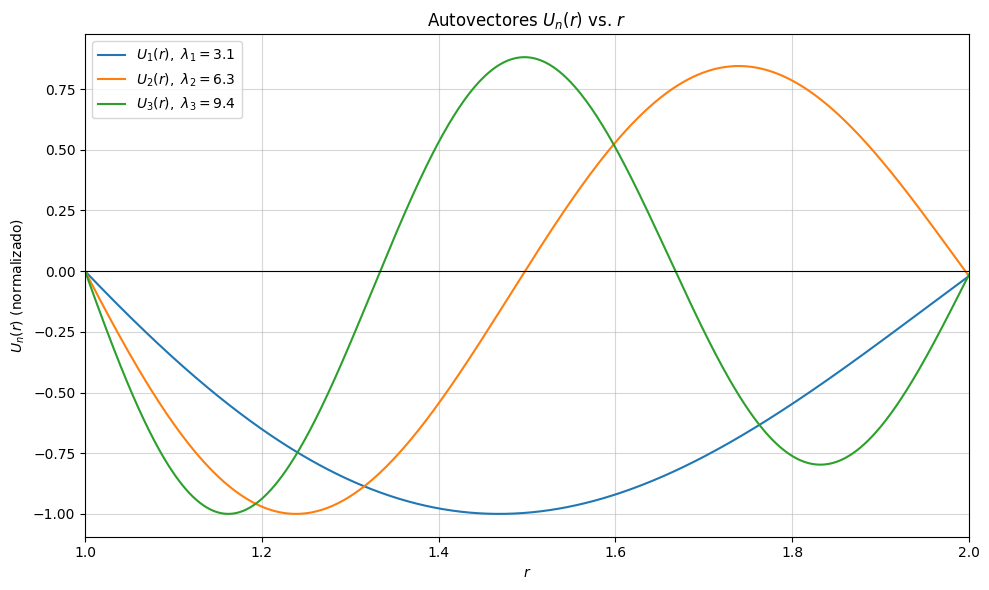

In [4]:
# Se reutilizan R1, R2 y las funciones de Bessel del apartado anterior.
# Se incluyen las importaciones para que esta sección también pueda ejecutarse por separado.
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import j0, y0

R1 = 1
R2 = 2
lambdas = [3.1, 6.3, 9.4]

r = np.linspace(R1, R2, 500)

plt.figure(figsize=(10, 6))

for n, lam_n in enumerate(lambdas, start=1):
    U_n = j0(lam_n*r)*y0(lam_n*R1) - y0(lam_n*r)*j0(lam_n*R1)
    U_n = U_n / np.max(np.abs(U_n))
    plt.plot(r, U_n, label=fr"$U_{n}(r),\ \lambda_{n}={lam_n}$")

plt.axhline(0, color="black", linewidth=0.8)
plt.xlim(R1, R2)
plt.xlabel(r"$r$")
plt.ylabel(r"$U_n(r)$ (normalizado)")
plt.title(r"Autovectores $U_n(r)$ vs. $r$")
plt.grid(True, alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

### Animación 3D de los primeros modos radiales

Para visualizar los tres primeros modos, se construye una superficie de revolución a partir de cada autofunción radial $$U_n(r)$$. La coordenada radial $$r$$ define la posición sobre el anillo, mientras que el ángulo $$\theta$$ permite representar la geometría en tres dimensiones.

La superficie se define como

$$
x=r\cos(\theta),\qquad y=r\sin(\theta),
$$

$$
z=U_n(r).
$$

Se utiliza una normalización de cada autofunción para facilitar la comparación visual. La animación recorre los tres modos estimados, mostrando la forma de cada uno sobre el dominio $$R_1\leq r\leq R_2$$.

Esta visualización representa los modos espaciales; no corresponde a la evolución temporal de la ecuación de onda. Como los autovalores se estimaron gráficamente, las superficies son aproximaciones de los modos correspondientes.

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from scipy.special import j0, y0
from IPython.display import HTML, display

# Reutilizar los valores del código anterior
R1 = 1
R2 = 2
lambdas = [3.1, 6.3, 9.4]

# Malla del anillo
r = np.linspace(R1, R2, 100)
theta = np.linspace(0, 2*np.pi, 100)
R, THETA = np.meshgrid(r, theta)

X = R * np.cos(THETA)
Y = R * np.sin(THETA)

def U(lam, r):
    # Autofunción que satisface la condición interior
    B = -j0(lam * R1) / y0(lam * R1)
    return j0(lam * r) + B * y0(lam * r)

# Calcular y normalizar los tres modos
modos = []
for lam in lambdas:
    Zr = U(lam, r)
    Zr = Zr / np.max(np.abs(Zr))
    modos.append(np.tile(Zr, (len(theta), 1)))

# Crear figura 3D
fig = plt.figure(figsize=(9, 7))
ax = fig.add_subplot(111, projection="3d")

def actualizar(i):
    ax.clear()

    Z = modos[i]

    ax.plot_surface(
        X, Y, Z,
        cmap="coolwarm",
        edgecolor="none",
        antialiased=True
    )

    ax.set_title(
        rf"Modo radial $U_{i+1}(r)$, "
        rf"$\lambda_{i+1}={lambdas[i]}$"
    )
    ax.set_xlabel("$x$")
    ax.set_ylabel("$y$")
    ax.set_zlabel("$U_n(r)$")

    ax.set_xlim(-R2, R2)
    ax.set_ylim(-R2, R2)
    ax.set_zlim(-1.1, 1.1)
    ax.set_box_aspect((1, 1, 0.6))
    ax.view_init(elev=30, azim=45)

    return []

anim = FuncAnimation(
    fig,
    actualizar,
    frames=len(lambdas),
    interval=1800,
    repeat=True,
    blit=False
)

plt.close(fig)
display(HTML(anim.to_jshtml()))

### Y ahora con más lambdas

In [6]:
from scipy.optimize import brentq

n = 100

def F(lam):
    return j0(lam*R1)*y0(lam*R2) - y0(lam*R1)*j0(lam*R2)

# Buscar cambios de signo en un intervalo amplio
lam_scan = np.arange(0.01, (n + 5)*np.pi + 2, 0.02)
F_scan = F(lam_scan)

indices = np.where(F_scan[:-1] * F_scan[1:] < 0)[0]

lambdas = np.array([
    brentq(F, lam_scan[i], lam_scan[i+1])
    for i in indices
])

lambdas = lambdas[:n]

print("Cantidad de autovalores:", len(lambdas))
print("Primeros 10 autovalores:")
print(lambdas[:10])

# Verificar la ecuación característica
print("Máximo |F(lambda_n)|:",
      np.max(np.abs(F(lambdas))))

Cantidad de autovalores: 100
Primeros 10 autovalores:
[ 3.12303092  6.27343571  9.41820754 12.56142319 15.70399789 18.84624804
 21.98831148 25.13025776 28.27212573 31.4139388 ]
Máximo |F(lambda_n)|: 3.77042147503559e-15


In [7]:
from matplotlib.animation import FuncAnimation
from IPython.display import HTML, display

# Malla 3D del anillo
r = np.linspace(R1, R2, 60)
theta = np.linspace(0, 2*np.pi, 60)
R, THETA = np.meshgrid(r, theta)

X = R * np.cos(THETA)
Y = R * np.sin(THETA)

def U(lam, r):
    # Combinación que satisface U(R1) = 0
    return (
        j0(lam*r)*y0(lam*R1)
        - y0(lam*r)*j0(lam*R1)
    )

# Calcular y normalizar los modos una sola vez
modos = []

for lam in lambdas:
    Zr = U(lam, r)
    Zr = Zr / np.max(np.abs(Zr))
    modos.append(np.tile(Zr, (len(theta), 1)))

fig = plt.figure(figsize=(9, 7))
ax = fig.add_subplot(111, projection="3d")

def actualizar(i):
    ax.clear()

    ax.plot_surface(
        X, Y, modos[i],
        cmap="coolwarm",
        edgecolor="none"
    )

    ax.set_title(
        rf"Modo {i+1}/ {n}, "
        rf"$\lambda_{{{i+1}}}={lambdas[i]:.4f}$"
    )
    ax.set_xlabel("$x$")
    ax.set_ylabel("$y$")
    ax.set_zlabel("$U_n(r)$")

    ax.set_xlim(-R2, R2)
    ax.set_ylim(-R2, R2)
    ax.set_zlim(-1.1, 1.1)
    ax.set_box_aspect((1, 1, 0.6))
    ax.view_init(elev=30, azim=45)

    return []

anim = FuncAnimation(
    fig,
    actualizar,
    frames=n,
    interval=250,
    repeat=True,
    blit=False
)

plt.close(fig)
display(HTML(anim.to_jshtml()))

### Animación temporal 3D de la vibración del anillo

La solución se representa mediante una combinación de los tres primeros modos radiales:

$$
u(r,t)=\sum_{n=1}^{3}a_n\cos(\lambda_n t)U_n(r).
$$

Se supone velocidad inicial nula, por lo que cada modo evoluciona mediante el factor temporal $$\cos(\lambda_n t)$$. Los coeficientes $$a_n$$ se eligen para ilustrar una deformación inicial; no corresponden a condiciones iniciales experimentales.

La coordenada vertical de la superficie representa el desplazamiento radial transversal $$u(r,t)$$. La animación permite observar cómo cambia la deformación del anillo con el tiempo.

In [9]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML, display
from scipy.special import j0, y0

# Usar los tres primeros autovalores calculados anteriormente
lambdas_3 = lambdas[:3]

# Malla espacial
r = np.linspace(R1, R2, 70)
theta = np.linspace(0, 2*np.pi, 70)
R, THETA = np.meshgrid(r, theta)

X = R * np.cos(THETA)
Y = R * np.sin(THETA)

# Autofunción radial que satisface U(R1) = 0
def U(lam, r):
    return (
        j0(lam*r)*y0(lam*R1)
        - y0(lam*r)*j0(lam*R1)
    )

# Normalizar los tres modos
modos = []
for lam in lambdas_3:
    Ur = U(lam, r)
    Ur = Ur / np.max(np.abs(Ur))
    modos.append(np.tile(Ur, (len(theta), 1)))

# Coeficientes ilustrativos de la deformación inicial
a = np.array([0.6, 0.3, 0.15])

# Tiempo de animación
t = np.linspace(0, 10, 160)

fig = plt.figure(figsize=(9, 7))
ax = fig.add_subplot(111, projection="3d")

def actualizar(i):
    ax.clear()

    # Superposición temporal de los tres modos
    Z = sum(
        a[k] * np.cos(lambdas_3[k] * t[i]) * modos[k]
        for k in range(3)
    )

    ax.plot_surface(
        X, Y, Z,
        cmap="coolwarm",
        edgecolor="none",
        antialiased=True
    )

    ax.set_title(f"Vibración del anillo: t = {t[i]:.2f}")
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.set_zlabel("u(r,t)")

    ax.set_xlim(-R2, R2)
    ax.set_ylim(-R2, R2)
    ax.set_zlim(-1.1, 1.1)
    ax.set_box_aspect((1, 1, 0.5))
    ax.view_init(elev=30, azim=45)

    return []

anim = FuncAnimation(
    fig,
    actualizar,
    frames=len(t),
    interval=50,
    repeat=True,
    blit=False
)

plt.close(fig)
display(HTML(anim.to_jshtml()))

Animation size has reached 21151082 bytes, exceeding the limit of 20971520.0. If you're sure you want a larger animation embedded, set the animation.embed_limit rc parameter to a larger value (in MB). This and further frames will be dropped.
